## Cost analysis and sample portfolio (50 homes)

**Purpose:** convert energy use into estimated cost with a flat electricity rate, check the Power BI cost page against Python, and create the tables for the sample consulting report (a 50-home portfolio).

**Input:** `fact_energyconsumption.csv` (created by the Dashboard data notebook). This file is not stored in the repository; run the K-means and Dashboard data notebooks first.

**Outputs:** three CSV files in `data/processed/`: `portfolio50_by_appliance.csv`, `portfolio50_by_home.csv` and `cost_assumptions.csv`.

**Requires:** pandas, numpy. Random seed: 42 (listed in this folder's README).

**Summary of findings:**
- At a flat rate of 33 c/kWh, the average estimated cost is $0.495 per measurement across all 500 homes.
- Air Conditioning and Heater together make up about 46.5% of the sample portfolio's estimated cost; every other appliance is 7% to 8%, and the Fridge is 1.9%.
- The sample portfolio is within about 2% of the 500-home average for every appliance. It was drawn at random, so this is expected and is not a finding about any real portfolio.
- No home stands out: the highest home in the portfolio is 8.6% above average, which is an ordinary result for the highest of 50 homes.
- Costs are shown per measurement, not per month or year (see the limitations at the end).

### 1. Load data and set the electricity rate

- Cost = kWh x a flat rate. The rate is a single assumption, kept in one place (`RATE`) so it can be changed and the notebook rerun.
- `RATE = 0.33` $/kWh is rounded from 33.14 c/kWh: the all-day price of the single/flat rate plan in the Ausgrid area (NSW), from the AER Default Market Offer 2026-27, read on 30 October 2026.
- Only the usage charge is used. The daily supply charge ($1.66 per day) is excluded because the data only holds energy per appliance.
- GST: the AER states that all DMO tariff caps include GST (Final determination, chapter 2), so the rate of 33.14 c/kWh includes GST.
- The same rate must be used in the Power BI parameter `Electricity rate`, otherwise the two will not match.
- The rate is indicative and is not a bill.
- Source: AER, Default market offer prices 2026-27: Final determination, May 2026, chapter 2 (Table 2.1 and Figure 2.1)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---- 1. Assumptions (same as the Power BI parameter) ----
RATE = 0.33                      # $ per kWh, rounded from the AER's 33.14 c/kWh
RATE_SOURCE = "AER Default Market Offer 2026-27, Ausgrid NSW flat rate, incl. GST, usage charge only"
RATE_DATE = "2026-10-30"

fact = pd.read_csv("../data/processed/fact_energyconsumption.csv")
fact["cost"] = fact["kwh"] * RATE

print(fact.shape)   

(100000, 9)


**Findings**
- 100,000 rows: the 8 original columns plus the new `cost` column.
- Cost is exactly proportional to kWh, so rankings and shares do not depend on the rate; only the dollar values do.

### 2. Check against Power BI

- Home 4 is selected on the Power BI Cost page with the rate set to 0.33.
- The values printed here are compared with the cards on that page: `Selected home(s)` and `All 500 homes`.
- This confirms that the DAX measures calculate the same as Python.

In [2]:
home = 4
one = fact[fact["home_id"] == home]

print("Home", home, "avg kWh:", round(one["kwh"].mean(), 2))                 
print("Home", home, "avg cost per measurement:", round(one["cost"].mean(), 2))  
print("All homes avg cost per measurement:", round(fact["cost"].mean(), 2))     


Home 4 avg kWh: 1.46
Home 4 avg cost per measurement: 0.48
All homes avg cost per measurement: 0.49


**Findings**
- Home 4: average 1.46 kWh and about $0.48 per measurement; all homes: about $0.49.
- Power BI shows $0.481 for Home 4 and $0.49 for all homes.
- Home 4 is 2.75% below the all-homes average, which matches the `Difference vs all homes` card.

### 3. Sample portfolio of 50 homes

- 50 homes are chosen at random from the 500 homes, with a fixed seed (42), so the same homes are selected every time.
- This stands in for a property developer's 50 units. For a real client, replace `portfolio_ids` with the client's list of home IDs and rerun the notebook.
- The portfolio table is a subset of the readings: all measurements of the 50 chosen homes.

In [3]:
rng = np.random.default_rng(42)   # fixed seed so the same 50 homes are used every run
all_homes = np.sort(fact["home_id"].unique())
portfolio_ids = np.sort(rng.choice(all_homes, size=50, replace=False))
portfolio = fact[fact["home_id"].isin(portfolio_ids)]

print("Homes in portfolio:", portfolio["home_id"].nunique())
print("Measurements in portfolio:", len(portfolio))

Homes in portfolio: 50
Measurements in portfolio: 10158


**Findings**
- 50 homes and 10,158 measurements, about 203 per home (200 in the full dataset).
- Because the homes are drawn at random, the portfolio is expected to look like the 500-home benchmark.

### 4. Cost by appliance

- For each appliance: average kWh per measurement for the portfolio and for all 500 homes, and the same values converted to dollars.
- `share_of_cost_pct` is each appliance's share of the portfolio's total kWh. This is a fair share of cost because every appliance has about the same number of measurements (9,905 to 10,201 in the full dataset).
- The Power BI card `Air Conditioning + Heater` averages each appliance first, so it can differ from this column by one or two points.

In [4]:
by_appliance = pd.DataFrame({
    "portfolio_avg_kwh": portfolio.groupby("appliance")["kwh"].mean(),
    "all_homes_avg_kwh": fact.groupby("appliance")["kwh"].mean(),
})
by_appliance["portfolio_avg_cost"] = by_appliance["portfolio_avg_kwh"] * RATE
by_appliance["all_homes_avg_cost"] = by_appliance["all_homes_avg_kwh"] * RATE

# Share of the portfolio's estimated cost (each appliance has a similar number of measurements)
by_appliance["share_of_cost_pct"] = (
    portfolio.groupby("appliance")["kwh"].sum() / portfolio["kwh"].sum() * 100
)

by_appliance = by_appliance.round(3).sort_values("portfolio_avg_cost", ascending=False)
by_appliance


,portfolio_avg_kwh,all_homes_avg_kwh,portfolio_avg_cost,all_homes_avg_cost,share_of_cost_pct
appliance,,,,,
Heater,3.514,3.487,1.159,1.151,22.731
Air Conditioning,3.505,3.500,1.157,1.155,23.756
Microwave,1.110,1.101,0.366,0.363,7.049
Lights,1.108,1.087,0.366,0.359,7.365
Washing Machine,1.103,1.101,0.364,0.363,7.885
Dishwasher,1.103,1.103,0.364,0.364,7.533
Oven,1.098,1.103,0.362,0.364,7.459
Computer,1.094,1.095,0.361,0.362,7.097
TV,1.086,1.097,0.358,0.362,7.231


**Findings**
- Air Conditioning (3.505 kWh) and Heater (3.514 kWh) cost about $1.16 per measurement. Most other appliances cost about $0.36, and the Fridge about $0.10.
- Air Conditioning is 23.76% and Heater 22.73% of the portfolio's cost, together 46.5%. Each of the other seven appliances is 7.05% to 7.89% and the Fridge is 1.89%.
- The share of cost is the same at any electricity rate, because cost is proportional to energy.

### Difference from the 500-home average, by appliance

- For each appliance, the portfolio's average kWh is compared with the average of all 500 homes: (portfolio average / all-homes average - 1) x 100.
- The result is the same in kWh and in dollars, because cost is energy times a fixed rate.
- The values are added to the table as `difference_vs_all_pct`, so they are saved with the other outputs in section 6.

In [5]:
# Difference from the 500-home average, by appliance (in %)
port_kwh = portfolio.groupby("appliance")["kwh"].mean()
all_kwh = fact.groupby("appliance")["kwh"].mean()
diff_pct = ((port_kwh / all_kwh - 1) * 100).round(1)

by_appliance["difference_vs_all_pct"] = diff_pct   # saved with the other outputs in section 6
print(diff_pct.sort_values())
print("Lowest:", diff_pct.idxmin(), diff_pct.min(), "| highest:", diff_pct.idxmax(), diff_pct.max())

appliance
Fridge             -2.1
TV                 -1.0
Oven               -0.4
Computer           -0.2
Dishwasher         -0.1
Air Conditioning    0.1
Washing Machine     0.1
Heater              0.8
Microwave           0.8
Lights              1.9
Name: kwh, dtype: float64
Lowest: Fridge -2.1 | highest: Lights 1.9


**Findings**
- For every appliance the portfolio is within about 2% of the 500-home average, from 2.1% below (Fridge) to 1.9% above (Lights).
- Air Conditioning (+0.1%) and Heater (+0.8%), the two appliances that drive cost, are almost identical to the benchmark.
- A close match is expected: the 50 homes are a random sample of the 500, so these differences say nothing about any real portfolio.

In [12]:
# Illustration: Air Conditioning and Heater each use 10% less energy
share_ach = portfolio.loc[portfolio["appliance"].isin(["Air Conditioning", "Heater"]), "kwh"].sum() / portfolio["kwh"].sum()
saving_pct = 0.10 * share_ach * 100
saving_dollars = portfolio["cost"].mean() * 0.10 * share_ach
print(f"AC + Heater share of energy: {share_ach * 100:.2f}%")
print(f"Fall in estimated cost: {saving_pct:.2f}% (about ${saving_dollars:.3f} per measurement)")

AC + Heater share of energy: 46.49%
Fall in estimated cost: 4.65% (about $0.023 per measurement)


**Illustration (not a forecast):** if Air Conditioning and Heater each used 10% less energy, the portfolio's estimated cost per measurement would fall by about 4.65%, around 2 cents. This only applies the 10% to the share of energy these two appliances use (46.5%); the data cannot show whether such a saving is achievable.

### 5. Cost by home

- One row per portfolio home: number of measurements, average kWh, estimated average cost, and the difference from the all-homes average in per cent.
- Homes are sorted from highest to lowest cost. This ordering shows position only: in notebook 01, differences between homes were no larger than what random sampling produces (spread of home averages 0.080 kWh, about 5% of the mean).
- Homes have between 157 and 245 measurements, so averages are used rather than totals.

In [6]:
all_homes_avg_cost = fact["kwh"].mean() * RATE

by_home = (portfolio.groupby("home_id")
           .agg(n_measurements=("kwh", "size"), avg_kwh=("kwh", "mean"))
           .reset_index())
by_home["avg_cost"] = by_home["avg_kwh"] * RATE
by_home["difference_vs_all_pct"] = (by_home["avg_cost"] / all_homes_avg_cost - 1) * 100
by_home = by_home.round(3).sort_values("avg_cost", ascending=False)

print(by_home.head(5))
print("Portfolio avg cost per measurement:", round(portfolio["cost"].mean(), 3))
print("All homes avg cost per measurement:", round(all_homes_avg_cost, 3))


    home_id  n_measurements  avg_kwh  avg_cost  difference_vs_all_pct
12      176             207    1.630     0.538                  8.638
5        45             217    1.629     0.538                  8.630
25      297             183    1.628     0.537                  8.546
47      478             191    1.620     0.535                  8.007
20      236             221    1.617     0.534                  7.822
Portfolio avg cost per measurement: 0.495
All homes avg cost per measurement: 0.495


**Findings**
- The five highest homes are 176, 45, 297, 478 and 236, with 1.62 to 1.63 kWh per measurement ($0.53 to $0.54), which is 7.8% to 8.6% above the all-homes average.
- At a spread of about 5%, +8.6% is about 1.6 standard deviations, which is ordinary for the highest of 50 homes. These homes should not be described as high consumers.
- The portfolio's average cost per measurement ($0.495) is the same as all homes' ($0.495) at three decimals.
- The number of measurements differs by home (183 to 221 among the top five), which is another reason not to rank homes by total cost.

### 6. Save outputs

- `portfolio50_by_appliance.csv` and `portfolio50_by_home.csv` feed the tables and charts of the sample consulting report (50-home portfolio).
- `cost_assumptions.csv` records the rate, its source, the date, the number of portfolio homes and the seed, so that the analysis can be rerun and checked by someone else.
- The CSV files are created in `data/processed/` and are not stored in the repository. The figures made from them (section 7) are saved in `reports/figures/`.

In [7]:
by_appliance.to_csv("../data/processed/portfolio50_by_appliance.csv")
by_home.to_csv("../data/processed/portfolio50_by_home.csv", index=False)

pd.DataFrame([{
    "rate_per_kwh": RATE,
    "source": RATE_SOURCE,
    "date": RATE_DATE,
    "portfolio_homes": 50,
    "seed": 42,
}]).to_csv("../data/processed/cost_assumptions.csv", index=False)


### 7. Figures and appendix table for the report

- Two figures are drawn from the saved CSV files, so this section can be rerun without running the earlier cells:
  - Figure 1: average estimated cost per measurement by appliance, portfolio (50 homes) against all 500 homes.
  - Figure 2: each appliance's share of the portfolio's estimated cost.
- Dark green marks the portfolio, and Air Conditioning and Heater in Figure 2, so the two appliances that drive cost stand out. Grey marks the 500-home benchmark and the other appliances.
- The last cell prints the unit-by-unit table (one row per portfolio home) for Appendix A of the report.

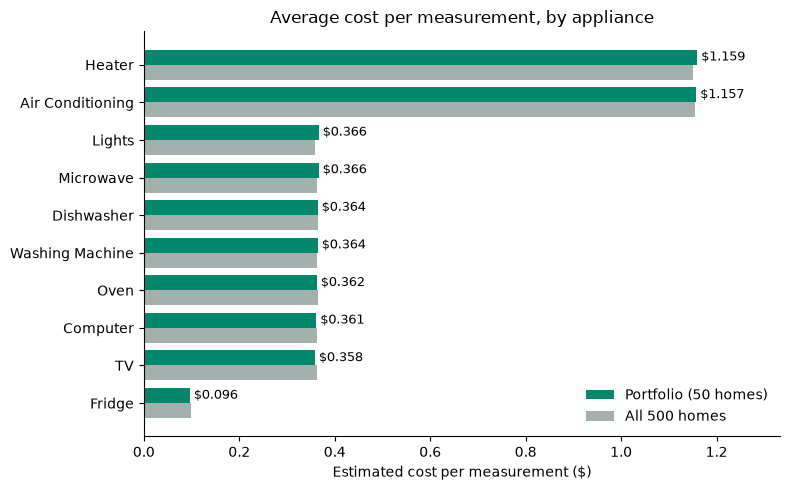

In [8]:
DARK, GREY = "#00876C", "#A3B0AD"
Path("../reports/figures").mkdir(parents=True, exist_ok=True)

# Read the files saved in section 6, so this cell works after a restart
by_appliance = pd.read_csv("../data/processed/portfolio50_by_appliance.csv", index_col="appliance")
by_home = pd.read_csv("../data/processed/portfolio50_by_home.csv")

# Figure 1: average cost per measurement by appliance
order = by_appliance.sort_values("portfolio_avg_cost").index
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(order))
b = ax.barh(y + 0.2, by_appliance.loc[order, "portfolio_avg_cost"], height=0.4, color=DARK, label="Portfolio (50 homes)")
ax.barh(y - 0.2, by_appliance.loc[order, "all_homes_avg_cost"], height=0.4, color=GREY, label="All 500 homes")
ax.bar_label(b, labels=[f"${v:.3f}" for v in by_appliance.loc[order, "portfolio_avg_cost"]], padding=3, fontsize=9)
ax.set_xlim(0, by_appliance["portfolio_avg_cost"].max() * 1.15)
ax.set_yticks(y)
ax.set_yticklabels(order)
ax.set_xlabel("Estimated cost per measurement ($)")
ax.set_title("Average cost per measurement, by appliance")
ax.legend(loc="lower right", frameon=False)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("../reports/figures/fig1_cost_by_appliance.png", dpi=200)
plt.show()

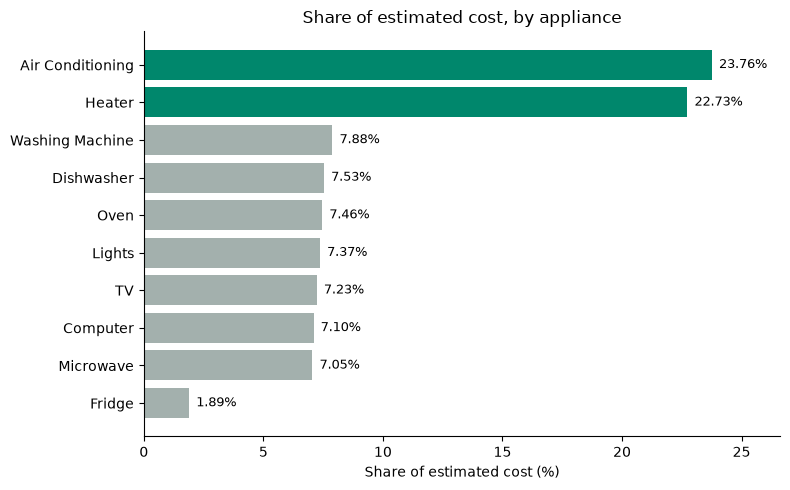

In [9]:
# Figure 2: share of the portfolio's estimated cost
share = by_appliance["share_of_cost_pct"].sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
colors = [DARK if a in ("Air Conditioning", "Heater") else GREY for a in share.index]
ax.barh(share.index, share.values, color=colors)
for i, v in enumerate(share.values):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center", fontsize=9)
ax.set_xlim(0, share.max() * 1.12)
ax.set_xlabel("Share of estimated cost (%)")
ax.set_title("Share of estimated cost, by appliance")
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("../reports/figures/fig2_cost_share.png", dpi=200)
plt.show()

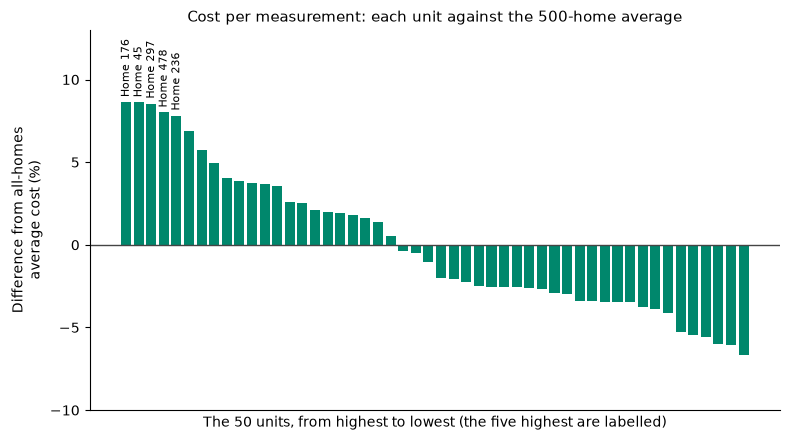

In [10]:
# Figure 3: each portfolio unit against the 500-home average
d = by_home.sort_values("difference_vs_all_pct", ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(d.index, d["difference_vs_all_pct"], color=DARK, width=0.8)
ax.axhline(0, color="#444444", linewidth=1)
for i in range(5):
    ax.text(i, d.loc[i, "difference_vs_all_pct"] + 0.3, f"Home {d.loc[i, 'home_id']}",
            ha="center", va="bottom", fontsize=8, rotation=90)
ax.set_xticks([])
ax.set_xlabel("The 50 units, from highest to lowest (the five highest are labelled)")
ax.set_ylabel("Difference from all-homes\naverage cost (%)")
ax.set_title("Cost per measurement: each unit against the 500-home average", fontsize=11)
ax.set_ylim(-10, 13)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("../reports/figures/fig3_units_vs_average.png", dpi=200)
plt.show()

- All 50 units are between 6.7% below and 8.6% above the 500-home average cost per measurement (22 units above, 28 below). No unit is far from the middle (Figure 3).

In [11]:
# Appendix A table (one row per portfolio home), printed so it can be pasted into the report
lines = ["| Home | Measurements | Avg kWh | Avg cost ($) | Difference from average |",
         "| --- | --- | --- | --- | --- |"]
for r in by_home.sort_values("home_id").itertuples(index=False):
    lines.append(f"| {r.home_id} | {r.n_measurements} | {r.avg_kwh:.3f} | {r.avg_cost:.3f} | {r.difference_vs_all_pct:+.1f}% |")
print("\n".join(lines))

| Home | Measurements | Avg kWh | Avg cost ($) | Difference from average |
| --- | --- | --- | --- | --- |
| 32 | 228 | 1.493 | 0.493 | -0.5% |
| 34 | 199 | 1.525 | 0.503 | +1.6% |
| 40 | 200 | 1.586 | 0.523 | +5.8% |
| 41 | 201 | 1.530 | 0.505 | +2.0% |
| 44 | 192 | 1.418 | 0.468 | -5.5% |
| 45 | 217 | 1.629 | 0.538 | +8.6% |
| 60 | 206 | 1.462 | 0.482 | -2.5% |
| 82 | 208 | 1.553 | 0.513 | +3.5% |
| 87 | 200 | 1.463 | 0.483 | -2.5% |
| 93 | 192 | 1.449 | 0.478 | -3.4% |
| 110 | 215 | 1.538 | 0.507 | +2.5% |
| 136 | 201 | 1.574 | 0.520 | +5.0% |
| 176 | 207 | 1.630 | 0.538 | +8.6% |
| 192 | 202 | 1.469 | 0.485 | -2.0% |
| 198 | 172 | 1.456 | 0.480 | -2.9% |
| 200 | 195 | 1.448 | 0.478 | -3.5% |
| 212 | 197 | 1.449 | 0.478 | -3.4% |
| 213 | 207 | 1.539 | 0.508 | +2.6% |
| 217 | 216 | 1.603 | 0.529 | +6.9% |
| 222 | 213 | 1.466 | 0.484 | -2.3% |
| 236 | 221 | 1.617 | 0.534 | +7.8% |
| 240 | 203 | 1.448 | 0.478 | -3.5% |
| 243 | 197 | 1.410 | 0.465 | -6.0% |
| 262 | 222 | 1.455 | 0.480 |

**Findings**
- Air Conditioning and Heater cost about $1.16 per measurement in the portfolio, against about $0.36 for most other appliances and $0.10 for the Fridge. The portfolio's bars are almost the same length as the 500-home bars for every appliance.
- Air Conditioning (23.8%) and Heater (22.7%) together make up 46.5% of the portfolio's estimated cost. Each of the other seven appliances is 7.0% to 7.9%, and the Fridge is 1.9%.
- The printed table lists all 50 portfolio homes and is used in Appendix A of the report.

### Conclusion and limitations

- At a flat rate of 33 c/kWh, the average estimated cost is $0.495 per measurement. Air Conditioning and Heater account for about 46.5% of the portfolio's cost and are the only appliances that stand out.
- The sample portfolio matches the 500-home average within 2% for every appliance. It was drawn at random, so this shows the method works, not that a real developer's units are typical.
- No single home stands out. Rankings and shares show position only and should not be read as wasteful use.
- The rate is indicative: one region (Ausgrid, NSW), usage charge only, flat rate (time-of-use pricing is not modelled), and GST treatment as stated in section 1.
- Costs are per measurement, not per month or year. Each home has only about 200 measurements, and the interval between measurements has not been confirmed, so no yearly figure is calculated.
- The dataset appears to be simulated (no seasonal pattern, household size varies within every home), so these findings may not apply to real data.